# Publishing the experiment record

Every training run writes its per-step history to `data/processed/` and its configuration and chosen checkpoint to a JSON record beside it. This notebook publishes those to Weights & Biases so the runs can be read without cloning the repository.

**These are backfilled.** The runs executed first and were written to CSV; this notebook replays them. Nothing here re-runs training or changes a number. If a curve looks wrong in W&B, the CSV is the source of truth.

The arm comparison is logged as a table, because each arm is one scored row. The rows come from `notebooks/04_arms.ipynb` and `notebooks/05_reranker.ipynb`, scored against the same holdout test set.

In [1]:
import json, os, pathlib, tempfile
import pandas as pd

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
import sys
sys.path.insert(0, str(ROOT))
from src.config import load_local_env, require_env
load_local_env(ROOT / ".env")

os.environ["WANDB_SILENT"] = "true"
# The wandb build reports a private mirror URL, so the shareable link is built below.
# WANDB_DIR goes to temp to keep per-run log files out of the repository.
os.environ["WANDB_DIR"] = tempfile.gettempdir()
import wandb
wandb.login(key=require_env("WANDB_API_KEY"), verify=True)
PROJECT = "metabolite-prediction"
ENTITY = wandb.Api().default_entity
print(f"logging to {ENTITY}/{PROJECT}")


logging to dianjiang75/metabolite-prediction


In [2]:
STEP_METRICS = ["loss", "dev_loss", "dev_recall5", "dev_recall1",
                "pct_of_ceiling5", "unreadable", "parent_echo",
                "any_hit", "precision", "usable"]

def replace(run_id):
    """A backfill is a replay, so running this notebook twice must leave one record, not two.
    Runs are given stable ids and any previous one is deleted first; resuming instead would
    append the replay to the history already there."""
    try:
        wandb.Api().run(f"{ENTITY}/{PROJECT}/{run_id}").delete()
        print(f"  replaced existing run {run_id}")
    except Exception:
        pass                                    # nothing to replace

def publish(history_csv, run_json, name, notes, folder="data/processed"):
    """Replay one saved training history into a W&B run."""
    hist = pd.read_csv(ROOT / folder / history_csv)
    rec = json.loads((ROOT / folder / run_json).read_text())
    checkpoints = rec.pop("all_checkpoints", {})
    cfg = {k: v for k, v in rec.items() if not k.startswith(("probe_", "full_", "unseen_",
                                                            "untuned_", "final_", "best_"))}
    replace(name)
    run = wandb.init(project=PROJECT, name=name, id=name, config=cfg, notes=notes,
                     job_type="backfill", reinit=True)
    cols = [c for c in STEP_METRICS if c in hist.columns]
    for row in hist.itertuples():
        payload = {c: getattr(row, c) for c in cols if pd.notna(getattr(row, c))}
        if payload:
            run.log(payload, step=int(row.step))
    run.summary.update({k: v for k, v in rec.items() if isinstance(v, (int, float, str))})
    run.summary["checkpoints_saved"] = len(checkpoints)
    url = run.url
    run.finish()
    print(f"  {name}: {len(hist):,} steps, "
          f"{hist[cols[0]].notna().sum():,} loss points -> {url}")
    return url

urls = {}
urls["generator"] = publish(
    "finetune_history.csv", "finetune_run.json", "generator-sft",
    "LoRA fine-tune to WRITE metabolites. Dev loss bottoms out in epoch 0 and then rises "
    "while dev recall keeps climbing, so the checkpoint is selected on dev recall@5, not on loss.")
urls["reranker"] = publish(
    "reranker_base_history.csv", "reranker_base_run.json", "reranker-sft-base",
    "LoRA fine-tune to RANK rule-enumerated candidates (parent + candidate -> yes/no). "
    "Training mix: DrugBank + GLORYx + MetXBioDB.")

# A second ranking run is detected by training-set size: the baseline record has no mix label.
latest = ROOT / "data/processed/reranker_run.json"
base = json.loads((ROOT / "data/processed/reranker_base_run.json").read_text())
rec = json.loads(latest.read_text()) if latest.exists() else {}
is_second = rec.get("training_mix", "base") != "base" or \
            rec.get("train_examples") not in (None, base.get("train_examples"))
if is_second:
    urls["reranker_gostar"] = publish(
        "reranker_history.csv", "reranker_run.json", "reranker-sft-gostar",
        "Same ranking objective, training mix extended with GOSTAR mammalian records "
        "(bacterial Ames-test rows excluded).")
else:
    print(f"  reranker-sft-gostar: no second run yet "
          f"({rec.get('train_examples')} examples, same as the baseline), skipped")


  generator-sft: 2,130 steps, 2,130 loss points -> https://forge.coreweave.com/wandb/dianjiang75/metabolite-prediction/runs/generator-sft


  reranker-sft-base: 2,000 steps, 2,000 loss points -> https://forge.coreweave.com/wandb/dianjiang75/metabolite-prediction/runs/reranker-sft-base


  reranker-sft-gostar: 5,040 steps, 5,040 loss points -> https://forge.coreweave.com/wandb/dianjiang75/metabolite-prediction/runs/reranker-sft-gostar


In [3]:
# The site predictor, if SOM/ has been run. Its curve is any_hit.
if (ROOT / "SOM/som_predictor_history.csv").exists():
    urls["site_predictor"] = publish(
        "som_predictor_history.csv", "som_predictor_run.json", "site-predictor",
        "LoRA fine-tune to mark the atom the body attacks, so the site filter can be driven by a "
        "prediction instead of a label. Selected on any_hit, not loss.", folder="SOM")
else:
    print("  site-predictor: SOM/ has not been run")

# Each arm is one scored row, all against the same holdout test set.
arms = pd.read_csv(ROOT / "docs/arm_results.csv", index_col=0).reset_index()
replace("arm-comparison")
run = wandb.init(project=PROJECT, name="arm-comparison", id="arm-comparison",
                 job_type="evaluation", reinit=True,
                 notes="Every arm scored by src/evaluation.py on the 309-pair holdout test set.")
run.log({"arms": wandb.Table(dataframe=arms)})
at5 = arms[arms["k"] == 5].set_index("arm")["recall_pair"]
run.summary.update({f"recall@5 | {a}": round(float(v), 4) for a, v in at5.items()})
# Attach the figures the written documents use, so the link carries the same evidence they do.
for png in ("finetune_curves.png", "arm_comparison.png", "reranker_curves.png"):
    p = ROOT / "docs" / png
    if p.exists():
        run.log({png.replace(".png", ""): wandb.Image(str(p))})
url = run.url
run.finish()
print(f"  arm-comparison -> {url}")
print(f"\n  as the client reports it : {url.rsplit('/runs/', 1)[0]}")
print(f"  shareable link          : https://wandb.ai/{ENTITY}/{PROJECT}")
print(f"\n  the project is private until it is switched to Public in the W&B UI"
      f" (project page -> lock icon -> Public)")


  site-predictor: 834 steps, 834 loss points -> https://forge.coreweave.com/wandb/dianjiang75/metabolite-prediction/runs/site-predictor


  arm-comparison -> https://forge.coreweave.com/wandb/dianjiang75/metabolite-prediction/runs/arm-comparison

  as the client reports it : https://forge.coreweave.com/wandb/dianjiang75/metabolite-prediction
  shareable link          : https://wandb.ai/dianjiang75/metabolite-prediction

  the project is private until it is switched to Public in the W&B UI (project page -> lock icon -> Public)


The project URL links to the uploaded experiment record. Training runs contain per-step
histories; `arm-comparison` contains the scored configuration table and figures.

## The two ranking runs

The base and mammalian-GOSTAR mixtures each have one training run. The x-axis uses epochs, with
500 and 1,260 steps per epoch respectively. Equal epochs therefore correspond to different
optimizer-update budgets, as well as different data amounts and compositions.

Development recall is measured on 40 parent strings carrying 68 pairs. One pair changes the
score by about 1.5 points; references from a parent are dependent. Both runs selected their
maximum at epoch 1.5. The noisy nine-checkpoint trajectories do not establish a shared plateau
or data saturation. Test results are shown in the figure title.

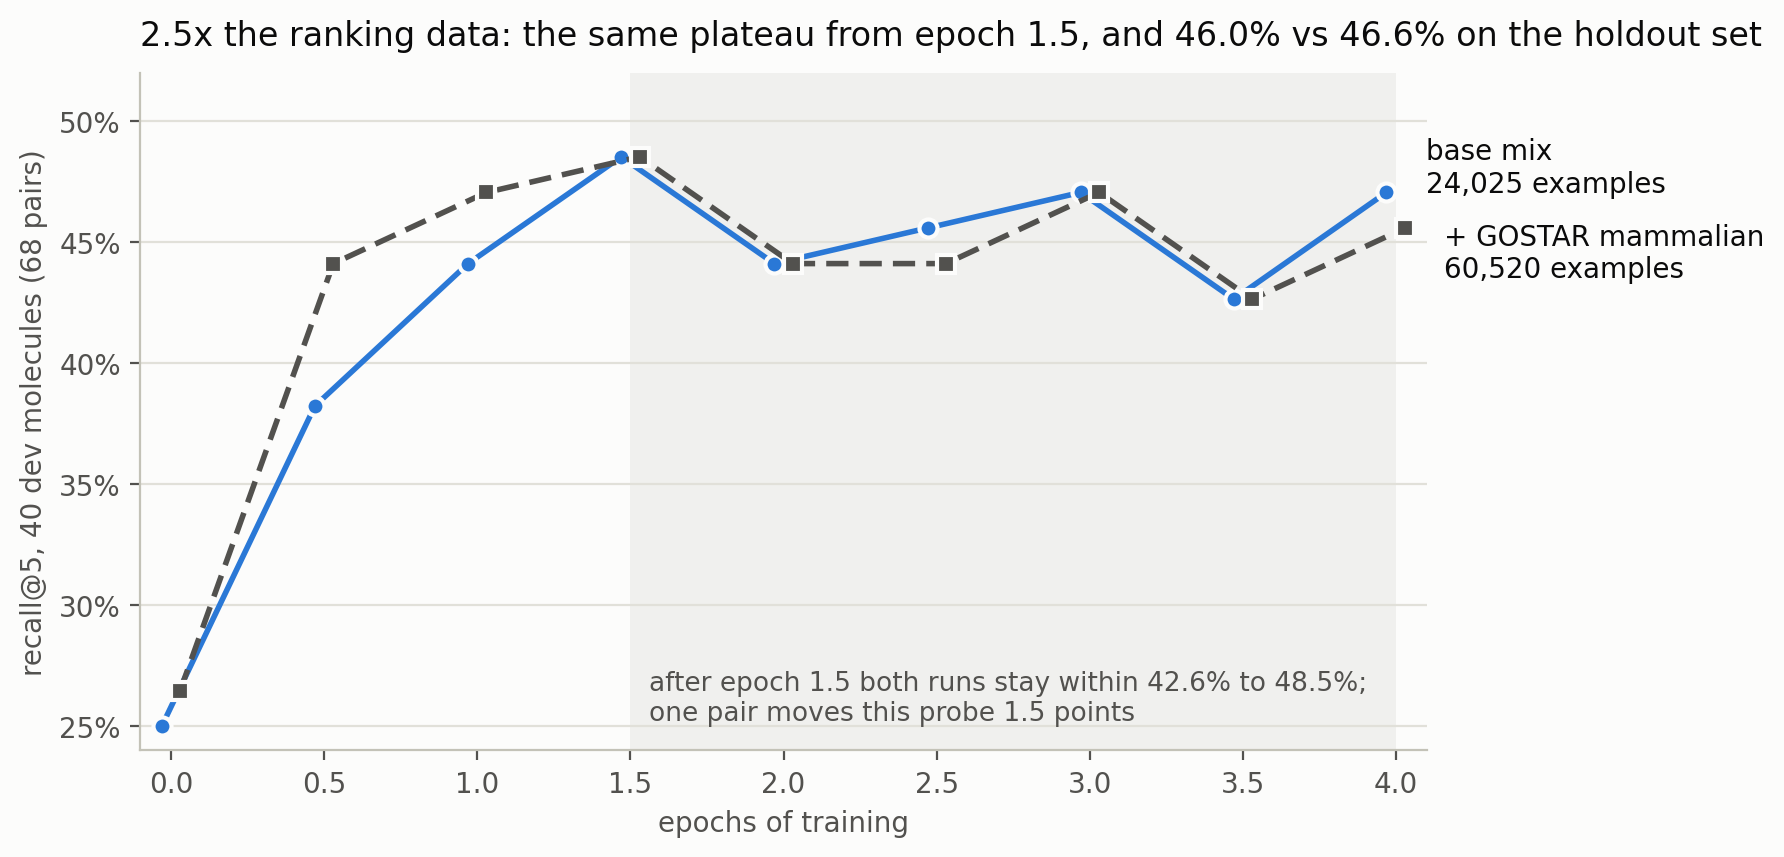

  plateau band from epoch 1.5: 42.6% to 48.5%

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Blue is the reported ranker; dark grey is the run with GOSTAR added. Same roles as every figure.
BLUE, DARK, GREY = "#2a78d6", "#52514e", "#898781"
INK, MUTED, GRID, LIGHT, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"

at5 = pd.read_csv(ROOT / "docs/arm_results.csv", index_col=0).loc[5].set_index("arm")["recall_pair"]
runs = []
for hist_csv, rec_json, arm, label, colour, marker, dx in (
        ("reranker_base_history.csv", "reranker_base_run.json", "6  tuned ranker (base mix)",
         "base mix", BLUE, "o", -0.03),
        ("reranker_history.csv", "reranker_run.json", "6  tuned ranker (+GOSTAR mammalian)",
         "+ GOSTAR mammalian", DARK, "s", 0.03)):
    h = pd.read_csv(ROOT / "data/processed" / hist_csv)
    rec = json.loads((ROOT / "data/processed" / rec_json).read_text())
    h["epoch_f"] = h["step"] / (rec["train_examples"] // rec["batch"])
    runs.append((h.dropna(subset=["dev_recall5"]), rec, at5[arm], label, colour, marker, dx))

fig, ax = plt.subplots(figsize=(8.3, 4.4))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
for s in ("left", "bottom"): ax.spines[s].set_color(LIGHT)
ax.tick_params(colors=MUTED, labelsize=10)

# The plateau is the observed range after epoch 1.5. One pair moves this probe
# 1.5 points, so the ups and downs inside it are not resolvable.
PLATEAU = 1.5
after = pd.concat([e[e["epoch_f"] >= PLATEAU]["dev_recall5"] for e, *_ in runs])
lo, hi = after.min(), after.max()
ax.axvspan(PLATEAU, 4.0, color=GREY, alpha=0.10, zorder=0, linewidth=0)
ax.text(PLATEAU + 0.06, 0.25, f"after epoch {PLATEAU} both runs stay within {lo:.1%} to {hi:.1%};\n"
        "one pair moves this probe 1.5 points", color=MUTED, fontsize=9.5, va="bottom")

for e, rec, test_r5, label, colour, marker, dx in runs:
    ax.plot(e["epoch_f"] + dx, e["dev_recall5"], color=colour, linewidth=2, marker=marker,
            markersize=6.5, markerfacecolor=colour, markeredgecolor=SURFACE, markeredgewidth=1.5,
            linestyle="-" if colour == BLUE else (0, (4, 2)))
    ax.annotate(f"{label}\n{rec['train_examples']:,} examples", xy=(4.0 + dx, e["dev_recall5"].iloc[-1]),
                xytext=(14, 9 if colour == BLUE else -9), textcoords="offset points", va="center",
                color=INK, fontsize=10)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(0.24, 0.52); ax.set_xlim(-0.1, 4.1)
ax.set_xticks([0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4])
ax.set_ylabel("recall@5, 40 dev molecules (68 pairs)", color=MUTED, fontsize=10)
ax.set_xlabel("epochs of training", color=MUTED, fontsize=10)
ax.set_title("Dev recall@5 over training: base mix against + GOSTAR mammalian",
             color=INK, fontsize=13, fontweight="bold", loc="left", pad=10)
plt.savefig(ROOT / "docs" / "reranker_curves.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print(f"  plateau band from epoch {PLATEAU}: {lo:.1%} to {hi:.1%}")